<a href="https://colab.research.google.com/github/PPGCA-MLG/2026S2/blob/main/Aula_08/3Yolov5_Resnet50_object_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Detecção de objetos: Exemplos usando arquiteturas `YOLOv5` e `ResNet-50`**

A **Detecção de Objetos** (_Object Detection_): Diferente da classificação simples (que atribui apenas um rótulo à imagem inteira), é uma tarefa da Visão Computacional que **identifica *o que* está na imagem (classificação) e *onde* cada elemento está localizado (localização)**, desenhando uma caixa delimitadora (*bounding box*) ao redor de cada objeto detectado.

* **Arquitetura YOLO** (*You Only Look Once*): é uma arquitetura de detecção em **estágio único (*one-stage detector*)** projetada para alta velocidade e tempo real. Ele divide a imagem em uma grade (*grid*) e, em uma única passagem pela rede neural, prevê simultaneamente as coordenadas das caixas delimitadoras, a probabilidade de haver um objeto e a classe correspondente. Neste notebook, utilizamos a versão leve **`YOLOv5s`**.

* **Arquitetura ResNet-50** (*Residual Network*): é uma CNN de 50 camadas, famosa pelo uso de **conexões residuais (*skip connections*)**, que ajudam a evitar o desvanecimento do gradiente (_vanishing gradient_)durante o treinamento. Observe que: a ResNet-50 original é uma rede de classificação (não desenha caixas por si própria). Para usá-la na detecção, ela é inserida como **extração de características** (*backbone*) dentro de um pipeline maior (como o *Faster R-CNN*), dividido em dois estágios (_two-stage detectors_):

  1. **ResNet-50** (*Backbone*): Extrai mapas de características visuais (bordas, texturas e formas) da imagem.
  2. **RPN** (*Region Proposal Network*): Sugere regiões candidatas onde podem existir objetos.
  3. **Cabeça de Detecção** (*RoI Head*): Classifica o objeto dentro de cada região sugerida e faz o ajuste fino (regressão) das coordenadas da *bounding box*.

Neste exemplo, empregamos o modelo pré-treinado `YOLOv5` para detectar objetos de interesse — dentre os 80 tipos reconhecidos pelo modelo — em 10 imagens de imóveis. Ao final, é produzido um vetor *one-hot encoded* indicando a presença (`1.0`) ou ausência (`0.0`) desses objetos em cada imagem:

```
id	            person ...chair	couch	 bed	...laptop	...refrigerator
/content/1.jpg	0.0	      1.0	  1.0	   0.0	   0.0	     0.0
/content/2.jpg	0.0	      1.0	  1.0	   0.0	   0.0	     0.0
...
/content/10.jpg	0.0	      1.0	  1.0	   0.0	   0.0	     0.0
```

Adicionalmente, incluímos a detecção de objetos por outro modelo pré-treinado baseado na arquitetura **`ResNet-50`**. Ambos os modelos foram pré-treinados sobre o mesmo conjunto de dados de referência, o **COCO Dataset** (https://cocodataset.org/), gerando resultados comparáveis.

### 1. Instalação de Dependências e Importação das Bibliotecas
Instalamos o repositório oficial do `YOLOv5` (Ultralytics) e importamos as bibliotecas essenciais:
* **`torch`:** Framework de Deep Learning utilizado para carregar e executar os modelos pré-treinados.
* **`cv2` (OpenCV) e `PIL`:** Leitura, manipulação de cores e desenho das caixas delimitadoras nas imagens.
* **`pandas`, `numpy` e `matplotlib`:** Estruturação dos resultados em tabelas (*DataFrames*) e visualização gráfica.

In [1]:
!pip install git+https://github.com/ultralytics/yolov5

#!pip install -q yolov5

# RESTART AFTER

  Cloning https://github.com/ultralytics/yolov5 to /tmp/pip-req-build-yhkcbzep
  Running command git clone --filter=blob:none --quiet https://github.com/ultralytics/yolov5 /tmp/pip-req-build-yhkcbzep
  Resolved https://github.com/ultralytics/yolov5 to commit 33ae15ef99bd04ce1d3f12155b8a85f355d73351
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'git+https://github.com/ultralytics/yolov5' when getting requirements to build wheel


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import torch
import cv2
from PIL import Image
from yolov5 import detect

/usr/local/lib/python3.13/dist-packages/yolov5/utils/general.py:34: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as pkg


### 2. Carregamento das Imagens
Nesta etapa, fazemos o download automático de 9 imagens de ambientes internos e externos de imóveis (`1.jpg` a `10.jpg`) para o diretório local do ambiente.

In [22]:
import os
import shutil
import subprocess

path_dataset = "/content/imoveis_images/"
base_url = "https://raw.githubusercontent.com/PPGCA-MLG/2026S2/refs/heads/main/Aula_08/dataset/"


shutil.rmtree(path_dataset, ignore_errors=True)
os.makedirs(path_dataset, exist_ok=True)

for i in range(1, 11):
    subprocess.run(["wget", "-q", "-P", path_dataset, f"{base_url}{i}.jpg"], check=False)

print("Arquivos baixados:", sorted(os.listdir(path_dataset)))

Arquivos baixados: ['1.jpg', '10.jpg', '2.jpg', '3.jpg', '4.jpg', '5.jpg', '6.jpg', '7.jpg', '8.jpg', '9.jpg']


### 3. Carregamento do modelo YOLOv5 e seleção de objetos de interesse

Carregamos o modelo pré-treinado **`yolov5s`** (versão *small*, rápida e leve) via `torch.hub`. O dataset **COCO** contem **80 classes padrão** que a rede é capaz de reconhecer.

In [23]:
# Carregar o modelo YOLOv5 pré-treinado
model = torch.hub.load('ultralytics/yolov5', 'yolov5s')

# Obter a lista de todos os objetos reconhecidos pelo YOLOv5
objects = model.names

# Imprimir a lista de objetos
COCO_INSTANCE_CATEGORY_NAMES = []

print("Lista de objetos reconhecidos pelo YOLOv5:")
for idx, obj in objects.items():
    print(f"ID: {idx}, Nome: {obj}")
    COCO_INSTANCE_CATEGORY_NAMES.append(obj)


YOLOv5 🚀 2026-11-23 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients
Adding AutoShape... 
Lista de objetos reconhecidos pelo YOLOv5:
ID: 0, Nome: person
ID: 1, Nome: bicycle
ID: 2, Nome: car
ID: 3, Nome: motorcycle
ID: 4, Nome: airplane
ID: 5, Nome: bus
ID: 6, Nome: train
ID: 7, Nome: truck
ID: 8, Nome: boat
ID: 9, Nome: traffic light
ID: 10, Nome: fire hydrant
ID: 11, Nome: stop sign
ID: 12, Nome: parking meter
ID: 13, Nome: bench
ID: 14, Nome: bird
ID: 15, Nome: cat
ID: 16, Nome: dog
ID: 17, Nome: horse
ID: 18, Nome: sheep
ID: 19, Nome: cow
ID: 20, Nome: elephant
ID: 21, Nome: bear
ID: 22, Nome: zebra
ID: 23, Nome: giraffe
ID: 24, Nome: backpack
ID: 25, Nome: umbrella
ID: 26, Nome: handbag
ID: 27, Nome: tie
ID: 28, Nome: suitcase
ID: 29, Nome: frisbee
ID: 30, Nome: skis
ID: 31, Nome: snowboard
ID: 32, Nome: sports ball
ID: 33, Nome: kite
ID: 34, Nome: baseball bat
ID: 35, Nome: baseball glo

Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


#### Filtragem de Classes Relevantes para Imóveis
Como o dataset COCO contém classes irrelevantes para o contexto imobiliário (como girafas, semáforos ou pranchas de surfe), selecionamos apenas os **17 IDs de interesse**, agrupados por ambiente:

**Área externa:**
```
ID: 0, Nome: person
ID: 1, Nome: bicycle
ID: 2, Nome: car
ID: 3, Nome: motorcycle
```
**Quartos e salas:**
```      
ID: 56, Nome: chair
ID: 57, Nome: couch
ID: 58, Nome: potted plant
ID: 59, Nome: bed
ID: 60, Nome: dining table
ID: 61, Nome: toilet
ID: 62, Nome: tv
ID: 63, Nome: laptop
```
**Cozinha:**
```                 
ID: 68, Nome: microwave
ID: 69, Nome: oven
ID: 70, Nome: toaster
ID: 71, Nome: sink
ID: 72, Nome: refrigerator
```

In [24]:
ID_of_interest = list(range(0,4)) + list(range(56,64)) + list(range(68,73))

labels_of_interest = []
for i in ID_of_interest:
  labels_of_interest.append(model.names[i])

print(labels_of_interest)

['person', 'bicycle', 'car', 'motorcycle', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator']


### 4. Detecção dos objetos de interesse

Abaixo, definimos a função auxiliar `display_image_with_boxes` para desenhar as coordenadas `(x1, y1, x2, y2)` previstas pelo modelo sobre cada imagem.

Em seguida, testamos a inferência em algumas imagens (`detected_objects`) e construímos tabela *one-hot encoding* apenas dos objetos presentes na imagem de interesse (`labels_of_interest`).

In [25]:
%matplotlib inline
# Função para exibir a imagem com as detecções
def display_image_with_boxes(image, results):
    for box in results.xyxy[0]:  # x1, y1, x2, y2, confidence, class
        x1, y1, x2, y2, conf, cls = box
        label = results.names[int(cls)]
        cv2.rectangle(image, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
        cv2.putText(image, label, (int(x1), int(y1) - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

In [14]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
# Mesma função original, só garantindo que receba uma imagem array (H, W, 3) e linhas [x1, y1, x2, y2, conf, cls]
def display_image_with_boxes(image, detections, class_names):
    img_draw = image.copy()
    for x1, y1, x2, y2, conf, cls in detections:
        label = f"{class_names[int(cls)]}: {conf:.2f}"
        cv2.rectangle(img_draw, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
        cv2.putText(img_draw, label, (int(x1), max(15, int(y1) - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    plt.imshow(cv2.cvtColor(img_draw, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

In [26]:
%matplotlib inline
# Função para exibir a imagem com as detecções
def display_image_with_boxes(image_rgb, detections, class_names):
    img_draw = image_rgb.copy()
    for x1, y1, x2, y2, conf, cls in detections: # x1, y1, x2, y2, confidence, class
        label = f"{class_names[int(cls)]}: {conf:.2f}"
        cv2.rectangle(img_draw, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
        cv2.putText(img_draw, label, (int(x1), max(15, int(y1) - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    plt.imshow(img_draw)
    plt.axis('off')
    plt.show()

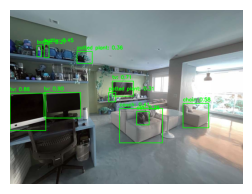

['tv', 'tv', 'tv', 'chair', 'bottle', 'couch', 'potted plant', 'potted plant', 'bottle', 'cat']


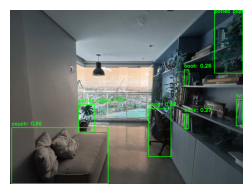

['potted plant', 'chair', 'couch', 'potted plant', 'tv', 'book', 'book']


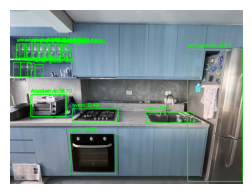

['refrigerator', 'oven', 'microwave', 'sink', 'toaster', 'wine glass', 'wine glass', 'oven', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass']


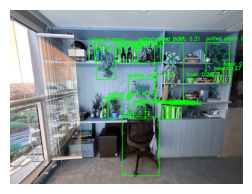

['chair', 'bottle', 'bottle', 'potted plant', 'potted plant', 'potted plant', 'bottle', 'potted plant', 'bottle', 'bottle', 'bottle', 'potted plant', 'book', 'book', 'book', 'potted plant', 'book', 'vase', 'bottle', 'book', 'potted plant', 'book', 'book', 'bowl', 'book']


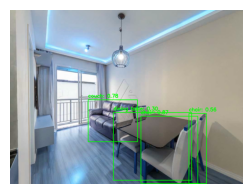

['chair', 'couch', 'chair', 'dining table']


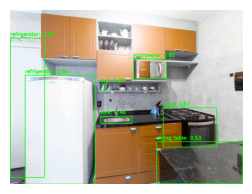

['oven', 'refrigerator', 'microwave', 'dining table', 'sink', 'refrigerator', 'cup']


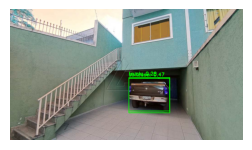

['suitcase', 'truck']


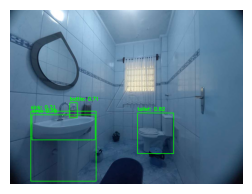

['toilet', 'sink', 'bottle', 'sink']


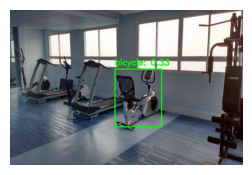

['bicycle']


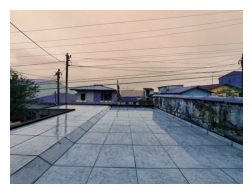

[]


,id,person,bicycle,car,motorcycle,chair,couch,potted plant,bed,dining table,toilet,tv,laptop,microwave,oven,toaster,sink,refrigerator
0,/content/imoveis_images/1.jpg,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,/content/imoveis_images/2.jpg,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,/content/imoveis_images/3.jpg,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
3,/content/imoveis_images/4.jpg,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,/content/imoveis_images/5.jpg,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,/content/imoveis_images/6.jpg,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0
6,/content/imoveis_images/7.jpg,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,/content/imoveis_images/8.jpg,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
8,/content/imoveis_images/9.jpg,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,/content/imoveis_images/10.jpg,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [27]:
path = path_dataset

nr_images = 10
id = []
hot_encode_objs = np.zeros((nr_images, len(labels_of_interest)))

for i in range(0, nr_images):
  image_path = path + str(i+1) + '.jpg'
  id.append(image_path)

  # Carregar imagem
  image = cv2.imread(image_path)

  # Realizar a detecção
  results = model(image)

  # Exibir a imagem com as caixas delimitadoras
  plt.figure(figsize=(3,3))
  #display_image_with_boxes(image.copy(), results)
  display_image_with_boxes(image.copy(), results.xyxy[0].cpu().numpy(), results.names)

  detected_objects = [results.names[int(cls)] for cls in results.xyxy[0][:, 5]]

  print(detected_objects)

  # Verificar a presença de cada rótulo de interesse
  presence = np.array([label in detected_objects for label in labels_of_interest])
  hot_encode_objs[i,:] = presence.astype(int)

pd.set_option("display.max_columns", 100)
df = pd.DataFrame(hot_encode_objs, columns=labels_of_interest)
df['id'] = id
df = pd.concat( [ df[['id']], df[df.columns[0:-1]] ] ,axis=1)
df

### 5. Comparação com detector baseado em `ResNet-50` (*Faster R-CNN*)

Neste exemplo usamos um modelo de detecção de objetos baseado na arquitetura **ResNet-50** (como o `fasterrcnn_resnet50_fpn` da biblioteca `torchvision`), também pré-treinado no dataset COCO.


In [28]:
COCO_INSTANCE_CATEGORY_NAMES = [
    '__background__', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus',
    'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'N/A', 'stop sign',
    'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow',
    'elephant', 'bear', 'zebra', 'giraffe', 'N/A', 'backpack', 'umbrella', 'N/A', 'N/A',
    'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball',
    'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket',
    'bottle', 'N/A', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl',
    'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza',
    'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'N/A', 'dining table',
    'N/A', 'N/A', 'toilet', 'N/A', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone',
    'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'N/A', 'book',
    'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush'
]

/content/imoveis_images/1.jpg Objetos:  ['tv', 'couch', 'potted plant', 'tv', 'tv', 'bottle', 'potted plant', 'tv', 'potted plant', 'potted plant', 'bottle', 'cup', 'potted plant', 'potted plant', 'bottle', 'potted plant', 'bottle', 'potted plant', 'bowl']


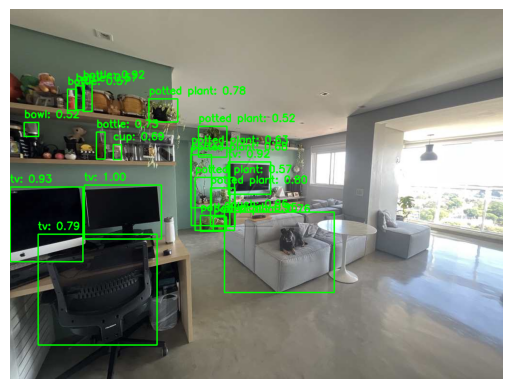

/content/imoveis_images/2.jpg Objetos:  ['potted plant', 'chair', 'potted plant', 'potted plant', 'couch', 'potted plant', 'potted plant', 'book', 'book', 'book', 'book', 'book', 'potted plant']


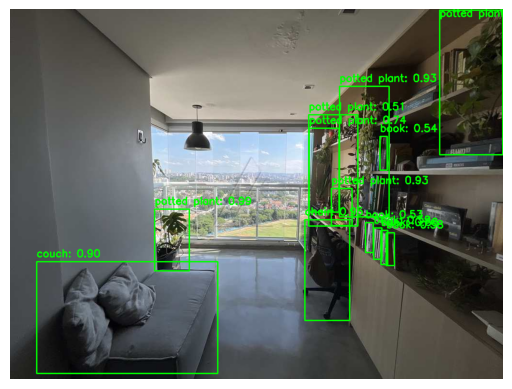

/content/imoveis_images/3.jpg Objetos:  ['refrigerator', 'knife', 'oven', 'knife', 'sink', 'wine glass', 'knife', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'oven', 'knife', 'wine glass', 'wine glass', 'wine glass', 'wine glass', 'knife', 'knife', 'cup', 'toaster', 'wine glass']


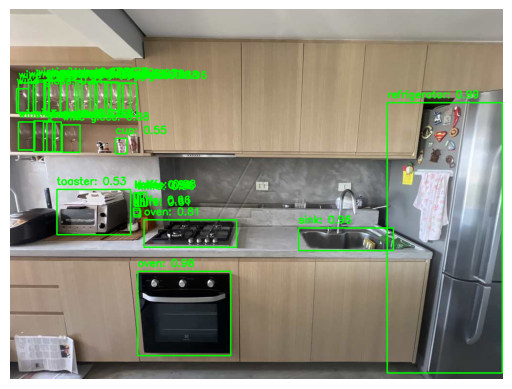

/content/imoveis_images/4.jpg Objetos:  ['potted plant', 'bottle', 'chair', 'bottle', 'bottle', 'potted plant', 'bottle', 'potted plant', 'bottle', 'book', 'potted plant', 'potted plant', 'bottle', 'tv', 'bottle', 'potted plant', 'book', 'potted plant', 'potted plant', 'bowl', 'vase', 'bottle', 'book', 'bottle', 'book', 'book', 'book', 'bottle', 'potted plant', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'cup', 'vase', 'refrigerator', 'vase', 'book', 'book', 'vase']


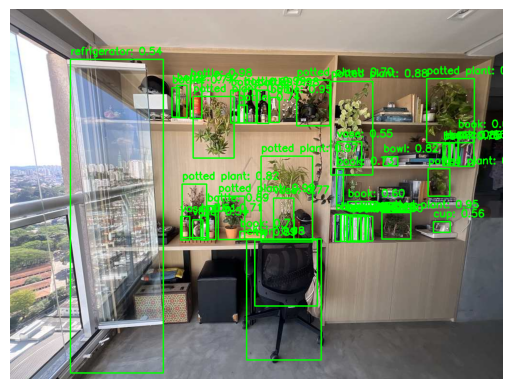

/content/imoveis_images/5.jpg Objetos:  ['chair', 'couch', 'dining table', 'chair', 'chair']


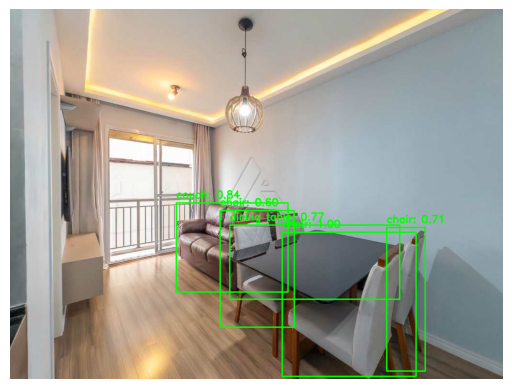

/content/imoveis_images/6.jpg Objetos:  ['oven', 'refrigerator', 'sink', 'cup', 'cup', 'cup', 'wine glass', 'cup', 'traffic light', 'microwave', 'wine glass', 'sink', 'wine glass', 'cup', 'dining table', 'cup', 'knife', 'cup', 'cup', 'cup', 'vase', 'cup', 'bowl', 'cup']


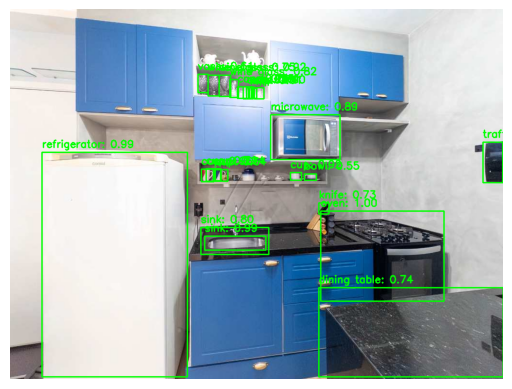

/content/imoveis_images/7.jpg Objetos:  ['truck']


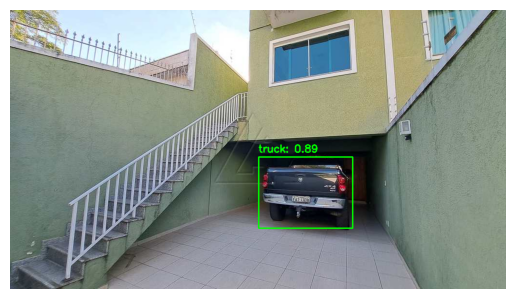

/content/imoveis_images/8.jpg Objetos:  ['toilet', 'sink', 'bottle', 'chair', 'sink', 'toilet', 'potted plant']


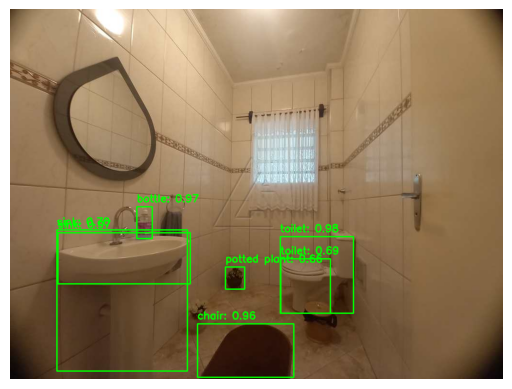

/content/imoveis_images/9.jpg Objetos:  ['chair', 'potted plant']


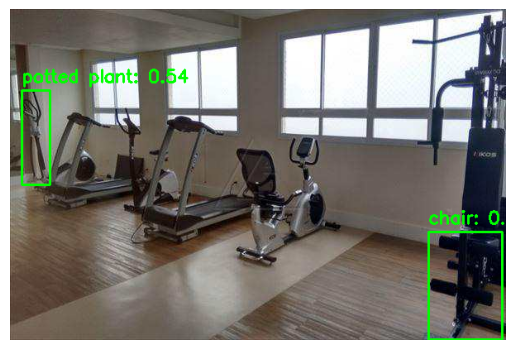

/content/imoveis_images/10.jpg Objetos:  ['bench', 'person']


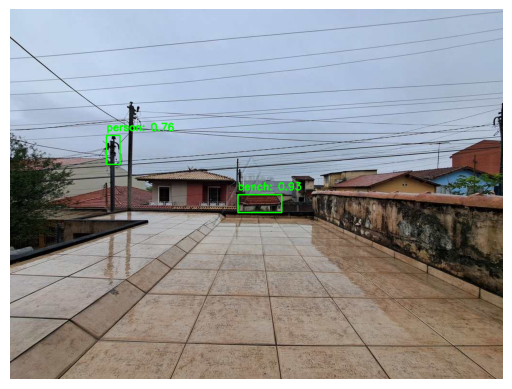

In [32]:
import numpy as np
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from PIL import Image
import torchvision.transforms as T

# Carregar o modelo pré-treinado no COCO
model = fasterrcnn_resnet50_fpn(pretrained=True)
model.eval()

transform = T.Compose([T.ToTensor()])

def process_image(image_path):
    pil_img = Image.open(image_path).convert("RGB")
    img_rgb = np.array(pil_img)
    image = transform(pil_img).unsqueeze(0)
    return image, img_rgb

# Carregar e processar a imagem
for i in range(0, nr_images):
    image_path = path + str(i+1) + '.jpg'

    image, img_rgb = process_image(image_path)

    # Fazer a previsão
    with torch.no_grad():
        predictions = model(image)

    # Extrair os resultados
    pred_boxes = predictions[0]['boxes'].cpu().numpy()
    pred_labels = predictions[0]['labels'].cpu().numpy()
    pred_scores = predictions[0]['scores'].cpu().numpy()

    # Filtrar resultados com base em uma pontuação mínima
    score_threshold = 0.5
    filtered_boxes = pred_boxes[pred_scores >= score_threshold]
    filtered_labels = pred_labels[pred_scores >= score_threshold]
    filtered_scores = pred_scores[pred_scores >= score_threshold]

    filtered_labels_names = [COCO_INSTANCE_CATEGORY_NAMES[k] for k in filtered_labels]

    # Imprimir os resultados
    print(image_path + " Objetos: ", filtered_labels_names)

    detections_rcnn = np.column_stack([filtered_boxes, filtered_scores, filtered_labels])
    display_image_with_boxes(img_rgb, detections_rcnn, COCO_INSTANCE_CATEGORY_NAMES)